# CNN - EuroSat Classification 

10-class land-use classification on a 10,000-image EuroSAT subset with a CNN trained from scratch (no pretrained weights).

Expected layout next to this notebook: `data/<ClassName>/*.jpg` (labelled) and `public_test_data/*.jpg` (unlabelled test images). The data is not part of this repository.

In [1]:
import numpy as np
import torch
import random
import torch.nn as nn
import math
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os
import pandas as pd
import glob
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg')

# Setting device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.backends.mps.is_available():
    device = torch.device("mps")

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [2]:
# checking successful setup
print(f"Using device: {device}")

Using device: mps


In [4]:
# For visualization in Jupyter notebooks
%matplotlib inline
plt.rcParams['figure.autolayout'] = True


In [ ]:
# Project folder = folder containing data/ and public_test_data/ (here: the folder this notebook is run from)
PROJECT_DIR = "."
os.chdir(PROJECT_DIR)
print(f"Current working directory: {os.getcwd()}")

In [ ]:
# creating folders for the plots and the model weights, if necessary
os.makedirs("assets/plots", exist_ok=True)
os.makedirs("assets/weights", exist_ok=True)

## Data Handling and Pre-Processing

In [7]:
# importing data from file system
def preprocess(data_folder: str) -> tuple[pd.DataFrame, dict]:
    #collecting all datapaths 
    files = glob.glob(f'{data_folder}/data/*/*.jpg')

    #converting datapaths to a pandas DF
    data = pd.DataFrame({
        'folder': files,
        'filename': [os.path.basename(f) for f in files],
        'label': [os.path.basename(os.path.dirname(f)) for f in files]
    })

    # convert text labels into numeric
    label_map = {
        'HerbaceousVegetation': 0,
        'AnnualCrop': 1,
        'Residential': 2,
        'Pasture': 3,
        'Industrial': 4,
        'River': 5,
        'Highway': 6,
        'Forest': 7,
        'PermanentCrop': 8,
        'SeaLake': 9
    }
    
    data['label'] = data['label'].map(label_map)
    
    return data, label_map

In [ ]:
# checking successful dataframe loading
dataset, labels = preprocess(os.getcwd())
print(f"Length of dataset: {len(dataset)}")


Length of dataset: 10000


In [9]:
# retrieving images and corresponding labels
X, y = dataset['folder'], dataset['label']

# train_set/val_set split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, train_size=0.90, random_state=42, stratify=y)

## Exploratory Data Analysis (EDA)

In [11]:
# show n random samples (5 is standard)
def show_samples(df: pd.DataFrame, num_samples: int = 5) -> None:
    samples = [i for i in np.random.randint(0, len(df), num_samples)] # get index number of random samples
    images = [plt.imread(df.iloc[i, 0]) for i in samples] # convert datapath into image for every sample
    name = [df.iloc[i, 1].split('_')[0] for i in samples] # HerbaceousVegetation_2752.jpg, extract nominal label
    

    cols = min(num_samples, 5) # cols of 5 for n > 5
    rows = math.ceil(num_samples / cols)
    
    fig, ax = plt.subplots(rows , cols, figsize=(cols * 2.5, rows *  3))

    for axis, img, label in zip(ax.flat, images, name): # ax.flat to get an array that can be iterated over
        axis.imshow(img)
        axis.axis('off') # clear ticks from images
        axis.set_title(f'Label: {label}')

    # remove redundant axis    
    for axis in ax.flat[num_samples:]: 
        axis.set_visible(False)
        
    plt.savefig('assets/plots/random_samples.png')





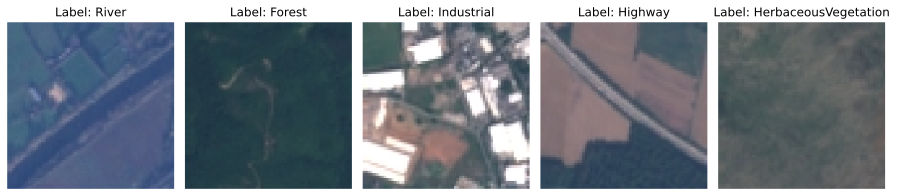

In [14]:
show_samples(dataset)

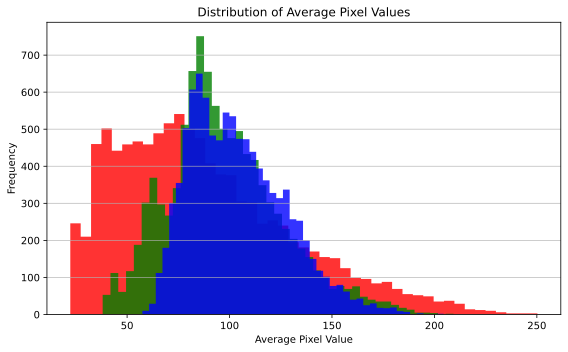

In [ ]:
# your code goes here (average_pixel_plot)
def average_pixel_plot(df: pd.DataFrame) -> None:
    averages = np.array([plt.imread(df.iloc[i, 0]).mean(axis=(0, 1)) for i in range(len(df))]) # plt.imread returns (64, 64, 3), average over each rgb channel

    fig, ax = plt.subplots(figsize=(8, 5))

    colors = ['red', 'green', 'blue']

    ax.hist(averages[:, 0], bins=45, alpha=0.8, color='red', histtype='stepfilled') # averages = np.arr (n, 3) where each col is a color
    ax.hist(averages[:, 1], bins=45, alpha=0.8, color='green', histtype='stepfilled')
    ax.hist(averages[:, 2], bins=45, alpha=0.8, color='blue', histtype='stepfilled')

    ax.set_title('Distribution of Average Pixel Values')
    ax.set_xlabel('Average Pixel Value')
    ax.set_ylabel('Frequency')
    ax.set_yticks(range(0, 800, 100))
    ax.yaxis.grid(True, linestyle='-', alpha=0.8)
    
    plt.tight_layout()
    plt.savefig("assets/plots/average_pixel_distribution.png")
    

average_pixel_plot(dataset)

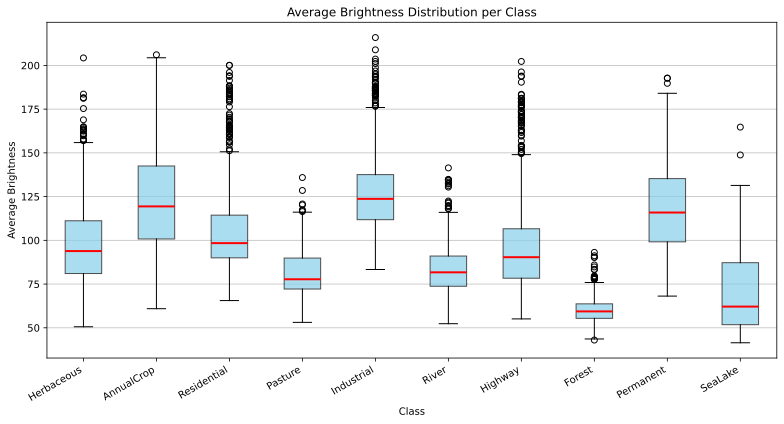

In [ ]:
def average_brightness_per_class(df: pd.DataFrame) -> None:
    df = df.copy()
    df['brightness'] = [plt.imread(df.iloc[i, 0]).mean() for i in range(len(df))] # add brightnes for every sample to new df (new col)

    class_names = ['Herbaceous', 'AnnualCrop', 'Residential', 'Pasture', 'Industrial','River', 'Highway', 'Forest', 'Permanent', 'SeaLake']
    data = [df[df['label'] == c]['brightness'] for c in range(0,10)] # list with a pd.series of valuesn(brightness), per class

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.boxplot(data, labels=class_names, patch_artist=True, boxprops=dict(facecolor='skyblue', alpha=0.7), medianprops=dict(color='red', linewidth=2))

    ax.set_title('Average Brightness Distribution per Class')
    ax.set_xlabel('Class')
    ax.set_ylabel('Average Brightness')
    ax.yaxis.grid(True, linestyle='-', alpha=0.8)
    ax.set_axisbelow(True)
    plt.xticks(rotation=30, ha='right')
    
    plt.tight_layout()
    plt.savefig('assets/plots/average_brightness.png')
    

   

average_brightness_per_class(dataset)

## CNN Implementation and Training

### Dataset class

In [17]:
class EuroSATData(Dataset):
    def __init__(self, data_paths, data_labels, transform=None):
        self.data_paths = data_paths
        self.labels = data_labels
        self.transform = transform

    def __len__(self):
        return len(self.data_paths)
    
    def __getitem__(self, idx):
        image = Image.open(self.data_paths.iloc[idx])
        label = self.labels.iloc[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

        

### Data Loaders

In [18]:

"""
# load all training images into one np array (n, 64, 64, 3)
data = np.array([np.array(Image.open(path)) for path in X_train]) # only compute normalization values over train set to avoid data leakage

# compute mean and std over all images, rows, and cols at once
# (n, 64, 64, 3) to (3,)
mean = data.mean(axis=(0, 1, 2)) / 255.0  # divide by 255 to match ToTensor() scale
std  = data.std(axis=(0, 1, 2))  / 255.0
"""
# once computed by the above code
mean = [0.34368882, 0.38104076, 0.40845288]
std = [0.20109171, 0.13641693, 0.11618139]


In [19]:
# data augmentation for training set
train_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(90),
    T.ToTensor(),
    T.Normalize(mean, std)
])

# only standardise val and test set. No augmentation.
val_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std)
])

# instatiate dataset class
train_dataset = EuroSATData(X_train, y_train, transform=train_transform)
val_dataset   = EuroSATData(X_val,   y_val,   transform=val_transform)

# batch train and validation set
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=64, shuffle=False)

### Model Architecture

In [20]:
class sat_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_stack = nn.Sequential(
            # 1 conv block
            nn.Conv2d(3, 64, kernel_size=3, padding=1), # padding 1 to keep manual control of image size
            nn.BatchNorm2d(64), # keep activations more stable
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2), # size down image spatial size

            # 2 conv block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2),

            # 3 conv block
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            
            nn.MaxPool2d(2),
            
            # 4 conv block
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),

        )
        
        self.pool = nn.AdaptiveAvgPool2d((1,1))     # global pooling layer (512 x 1 x 1)
        self.classifier = nn.Sequential(
            nn.Flatten(),  # flatten into 1d array to make the data proccesseable for the linear layer
            nn.Linear(512, 256),                         
            nn.ReLU(), 
            nn.Dropout(0.5), # prevent overfitting via random removing nodes during training
            nn.Linear(256, 10),                               
        )
    
    def forward(self,x):
        x = self.conv_stack(x)
        x = self.pool(x)
        logits = self.classifier(x)
        return logits

### Training Loop

In [ ]:
model = sat_CNN().to(device) # instantiate model and move it onto device

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15,  gamma=0.5) # lr halves every 15 epochs

# training loop
def num_correct(y_hat, y):
    y_hat = y_hat.argmax(1)                            
    correct = (y_hat == y).sum()     # batch passes all elements in parallel. need to sum the predictions for the count                 
    return correct.item()                             
size = len(train_loader.dataset)

def train_epoch(train_loader, model, loss_fn, optimizer):
    model.train()
    running_loss = 0.0
    running_correct = 0

    for X, y in train_loader:
        # move batches to device
        X = X.to(device)
        y = y.to(device)

        y_hat = model(X) # get prediction from model
        loss = loss_fn(y_hat, y) # compute loss via lossfunction

        optimizer.zero_grad() # reset gradients to avoid accumulation over batches
        loss.backward() # backpropagate loss
        optimizer.step() # update parameters

        running_loss += loss.item() * len(y) # loss over the whole batch
        running_correct += num_correct(y_hat, y)
       

    avg_loss = running_loss / len(train_loader.dataset)
    accuracy = running_correct / len(train_loader.dataset)

    return avg_loss, accuracy


def val_epoch(val_loader, model, loss_fn):
    model.eval()
    running_loss = 0.0
    running_correct = 0

    with torch.no_grad():
        for X, y in val_loader:
            X = X.to(device)
            y = y.to(device)
            
            y_hat = model(X)
            loss = loss_fn(y_hat, y)

            running_loss += loss.item() * len(y)
            running_correct += num_correct(y_hat, y)

    avg_loss = running_loss / len(val_loader.dataset)
    accuracy = running_correct / len(val_loader.dataset)

    return avg_loss, accuracy

doc = {'train_loss': [], 'val_loss': [], 'val_acc': []} # wrapped in dict to reuse the var names and for convenience
best_val_acc = 0

# execution of the trainingloop in epochs
for epoch in range(120):
    train_loss, train_acc = train_epoch(train_loader, model, loss_fn, optimizer)
    val_loss, val_acc = val_epoch(val_loader, model, loss_fn)

    scheduler.step() # lr scheduler

    print(f"Epoch {epoch+1}: \n"
          f"train loss {train_loss:.4f}, train acc {train_acc*100:.2f}% | "
          f"val loss {val_loss:.4f}, val acc {val_acc*100:.2f}%")
    print("_"*70)

    doc['train_loss'].append(train_loss)
    doc['val_loss'].append(val_loss)
    doc['val_acc'].append(val_acc)
    
    #storing the best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        os.makedirs('assets/weights', exist_ok=True)
        torch.save(model.state_dict(), 'assets/weights/best_model.pth') # store the parameters of the best model
        print(f'NEW MODEL saved: val accuracy: {val_acc*100:.2f}%\n')





Epoch 1: 
train loss 1.1519, train acc 59.09% | val loss 0.8881, val acc 67.40%
______________________________________________________________________
NEW MODEL saved: val accuracy: 67.40%

Epoch 2: 
train loss 0.8633, train acc 69.93% | val loss 0.7936, val acc 72.20%
______________________________________________________________________
NEW MODEL saved: val accuracy: 72.20%

Epoch 3: 
train loss 0.7150, train acc 75.12% | val loss 0.8637, val acc 72.70%
______________________________________________________________________
NEW MODEL saved: val accuracy: 72.70%

Epoch 4: 
train loss 0.6813, train acc 75.87% | val loss 0.5422, val acc 81.60%
______________________________________________________________________
NEW MODEL saved: val accuracy: 81.60%

Epoch 5: 
train loss 0.5930, train acc 79.73% | val loss 0.5611, val acc 80.60%
______________________________________________________________________
Epoch 6: 
train loss 0.5731, train acc 80.18% | val loss 0.5089, val acc 83.40%
_________

## Model Evaluation

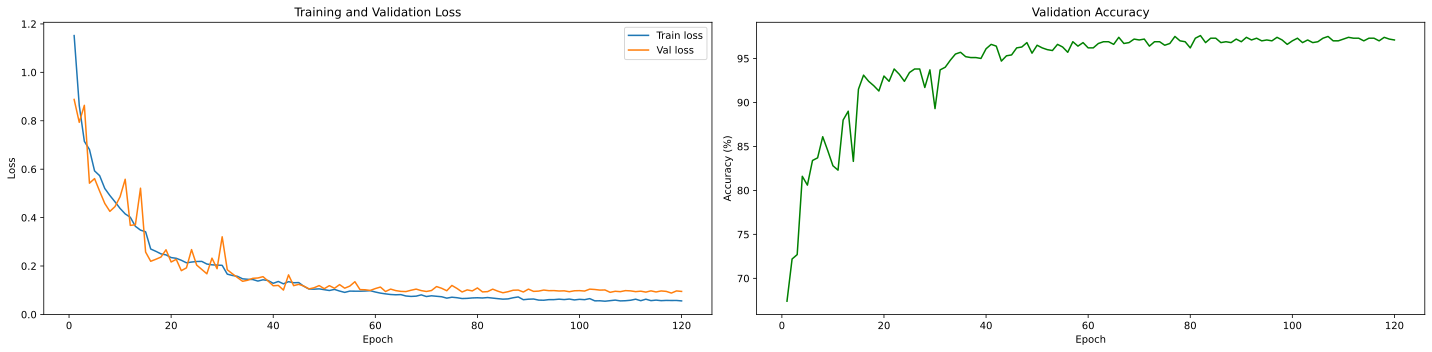

In [ ]:
# plot loss comparison and accuracy
def plot_performance(doc):
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,5))

    epochs = range(1, len(doc['train_loss']) + 1)

    # left plot, loss curves
    ax1.plot(epochs, doc['train_loss'], label='Train loss')
    ax1.plot(epochs, doc['val_loss'], label='Val loss')
    ax1.set_title('Training and Validation Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()

    # right plot, validation accuracy
    ax2.plot(epochs, [a * 100 for a in doc['val_acc']], color='green')
    ax2.set_title('Validation Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
                   
    plt.tight_layout()
    plt.savefig('assets/plots/model_performance.png')



plot_performance(doc)

In [24]:
# runs validation set through the best obtained model to collect needed data for visualization
def evaluate(val_loader, model):
    model.eval()
    pred_cm = [] # correct predictions of the model
    label_cm = [] # label of the predictions
    misclassified = []        # list of (validation set index, label, pred) for misclassified
    idx = 0

    with torch.no_grad():
        for X, y in val_loader:
            X = X.to(device)
            y = y.to(device)
            y_hat = model(X).argmax(1)
            pred_cm.extend(y_hat.tolist())
            label_cm.extend(y.tolist())

            for pred_iter, label_iter in zip(y_hat.tolist(), y.tolist()):
                if pred_iter != label_iter:
                    misclassified.append((idx, label_iter, pred_iter))
                idx += 1             # track index in the validation set

    return pred_cm, label_cm, misclassified


model.load_state_dict(torch.load('assets/weights/best_model.pth'))
pred_cm, label_cm, misclassified = evaluate(val_loader, model)

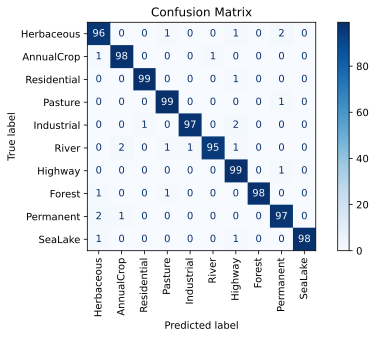

In [ ]:
# creates a confusion matrix comparing all classes
class_names = ['Herbaceous', 'AnnualCrop', 'Residential', 'Pasture', 'Industrial','River', 'Highway', 'Forest', 'Permanent', 'SeaLake']

ConfusionMatrixDisplay.from_predictions(label_cm, pred_cm, display_labels=class_names, xticks_rotation='vertical', cmap='Blues')
plt.title('Confusion Matrix')

plt.tight_layout()
plt.savefig('assets/plots/confusion_matrix.png')




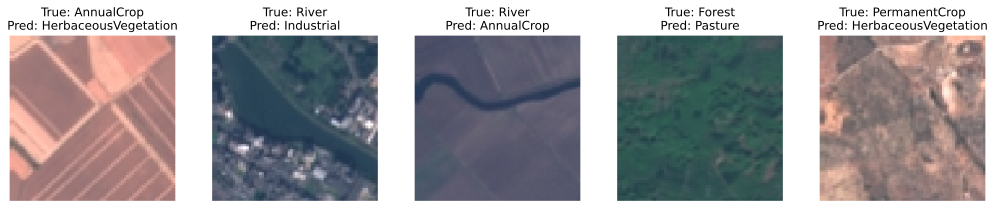

In [26]:
# plot 5 random samples that were misclassified by the best obtained model
def show_misclassified(wrong, val_dataset):
    samples = random.sample(wrong, 5)
    class_names = ['HerbaceousVegetation', 'AnnualCrop', 'Residential', 'Pasture', 'Industrial', 'River', 'Highway', 'Forest', 'PermanentCrop', 'SeaLake']

    fig, ax = plt.subplots(1, 5, figsize=(15, 3))

    for axis, (idx, true, pred) in zip(ax, samples):
        path = val_dataset.data_paths.iloc[idx] # vald_dataset.data_paths is the pd.Series dataset['folder']. Gives the path to the images.
        axis.imshow(plt.imread(path))
        axis.axis('off') # cleans image from axis ticks
        axis.set_title(f'True: {class_names[true]}\nPred: {class_names[pred]}')

    plt.savefig('assets/plots/misclassified_samples.png')


show_misclassified(misclassified, val_dataset)

### Test Set

In [27]:
# function to load data from file system
def preprocess_test(data_folder: str) -> pd.DataFrame:
    files = glob.glob(f"{data_folder}/public_test_data/*.jpg") # get image filepaths
    test_data = pd.DataFrame({'folder': files, 'filename': [os.path.basename(f) for f in files]}) # create df with filepath and names
    return test_data

In [28]:
#create test dataset class
class EuroSatTest(Dataset):
    def __init__(self, data_path, transform=None):
        self.data_path = data_path
        self.transform = transform
    
    def __len__(self):
        return len(self.data_path)

    def __getitem__(self, idx):
        image = Image.open(self.data_path.iloc[idx])
        if self.transform:
            image = self.transform(image)
        return image 

#load the data from file system and instatiate datasetclass. Put data into dataloader to extract batches.    
test_df = preprocess_test(os.getcwd())
test_dataset = EuroSatTest(test_df['folder'], transform=val_transform)   # same transform as validation set
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [29]:
# load best model and predict on test set
model.load_state_dict(torch.load('assets/weights/best_model.pth'))
model.eval()

predictions = []
with torch.no_grad():
    for X in test_loader:           # test loader yields images only. no labels
        X = X.to(device)
        preds = model(X).argmax(1)
        predictions.extend(preds.tolist())

# pair filenames with predictions in a df
submission = pd.DataFrame({
    'filename': test_df['filename'],
    'label': predictions
})

# convert numeric labels into text
inv_map = {
    0: 'HerbaceousVegetation',
    1: 'AnnualCrop',
    2: 'Residential',
    3: 'Pasture',
    4: 'Industrial',
    5: 'River',
    6: 'Highway',
    7: 'Forest',
    8: 'PermanentCrop',
    9: 'SeaLake'
}
    
submission['label'] = submission['label'].map(inv_map)

submission.to_csv('submission.csv', index=False, header=False) # submission csv with no index and no header